# Setup

Making sure the right python version is being used, because Python 3.7 or above is required for this project:

In [1]:
import sys

assert sys.version_info >= (3, 7)

Making sure the right Scikit-Learn version is being used, because Scikit-Learn 1.0.1 or above is required for this project:

In [2]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split

# Getting the Data for the house price file

Welcome to Assignment 1 for Introduction to Atrifical Intelligence Module. My task is to analyse the sales data of a large US based estate and improve their business operations using machine learning. My task includes cleaning up the given dataset, visualising critical information, and developing solutions using techniques learned from this module.

## Downloading the Data

In [4]:
houseprice_raw = pd.read_csv('As1datasets/houseprice.csv') #reading the dataset
original_df2 = houseprice_raw.copy() #keeping a copy of the original dataset

## Taking a Quick Look at the Data Structure

In [5]:
houseprice_raw.head()

,Price,Sqr Ft,Longitude,Latitude,Lot Size,Beds,Bath,Year Built,Last Sold Year,Last Sold For,Address,City,State,Zipcode,Address Full
0,"$895,900","3,447 sqft",-112.081985,33.560055,"7,895 sqft",4.0,4.5,2019.0,NaN,NaN,"630 W Echo Ln Phoenix, AZ 85021",Phoenix,AZ,85021.0,"630 W Echo Ln, Phoenix, AZ 85021"
1,"$247,000","1,767 sqft",-96.676250,32.829227,"7,877 sqft",3.0,2.0,1954.0,NaN,NaN,"2367 Highwood Dr Dallas, TX 75228",Dallas,TX,75228.0,"2367 Highwood Dr, Dallas, TX 75228"
2,"$44,900","1,232 sqft",-78.825190,42.913000,"3,510 sqft",3.0,1.0,1900.0,NaN,NaN,"30 Hurlock Ave Buffalo, NY 14211",Buffalo,NY,14211.0,"30 Hurlock Ave, Buffalo, NY 14211"
3,"$959,000","1,417 sqft",-73.860170,40.722960,"2,598 sqft",3.0,2.0,1939.0,2009.0,"$532,000","6416 Alderton St Flushing, NY 11374",Flushing,NY,11374.0,"6416 Alderton St, Flushing, NY 11374"
4,"$83,500",440 sqft,-80.206314,25.937965,NaN,NaN,1.0,1971.0,2007.0,"$52,000","251 NW 177th St #A-123 Miami Gardens, FL 33169",Miami Gardens,FL,33169.0,"251 NW 177th St #A-123, Miami Gardens, FL 33169"


In [6]:
houseprice_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30006 entries, 0 to 30005
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Price           30006 non-null  object 
 1   Sqr Ft          27786 non-null  object 
 2   Longitude       30006 non-null  float64
 3   Latitude        30006 non-null  float64
 4   Lot Size        25490 non-null  object 
 5   Beds            27420 non-null  float64
 6   Bath            27496 non-null  float64
 7   Year Built      26258 non-null  float64
 8   Last Sold Year  14213 non-null  float64
 9   Last Sold For   14213 non-null  object 
 10  Address         30006 non-null  object 
 11  City            30006 non-null  object 
 12  State           30006 non-null  object 
 13  Zipcode         30003 non-null  float64
 14  Address Full    30006 non-null  object 
dtypes: float64(7), object(8)
memory usage: 3.4+ MB


In [7]:
houseprice_raw["Last Sold For"].value_counts()

Last Sold For
$125,000      88
$175,000      82
$250,000      81
$150,000      81
$130,000      77
              ..
$53,947        1
$247,272       1
$193,697       1
$606,600       1
$5,500,000     1
Name: count, Length: 3868, dtype: int64

In [8]:
houseprice_raw.describe()

,Longitude,Latitude,Beds,Bath,Year Built,Last Sold Year,Zipcode
count,30006.000000,30006.000000,27420.000000,27496.000000,26258.000000,14213.000000,30003.000000
mean,-95.167341,36.158007,3.288658,2.578688,1973.140224,2011.110673,59349.268440
std,15.454027,5.500075,1.472238,1.448891,34.512400,6.596002,27206.130444
min,-150.047160,25.550295,1.000000,0.750000,1800.000000,1987.000000,2108.000000
25%,-106.742751,32.747084,3.000000,2.000000,1950.000000,2006.000000,33137.000000
50%,-93.390977,36.016481,3.000000,2.000000,1978.000000,2013.000000,68124.000000
75%,-81.638904,40.017658,4.000000,3.000000,2004.000000,2017.000000,85016.000000
max,-70.997740,61.442024,65.000000,98.000000,2019.000000,2019.000000,99587.000000


The following cell creates the `images/end_to_end_project` folder (if it doesn't already exist), and it defines the `save_fig()` function to save the figures in high-res for the book.

In [9]:
IMAGES_PATH = Path() / "As1images" / "end_to_end_project" #appends As1images to the folder, and appends end_to_end_project as its subfolder
IMAGES_PATH.mkdir(parents=True, exist_ok=True) #creates the folder if it does not already exist

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300): #creating a function to save the figures
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout: #if it has a tight layout then do the follwoing
        plt.tight_layout() #calling the tight_layout function
    plt.savefig(path, format=fig_extension, dpi=resolution) #saving the figure in the images folder

The following cell contains code for setting the the default font sizes

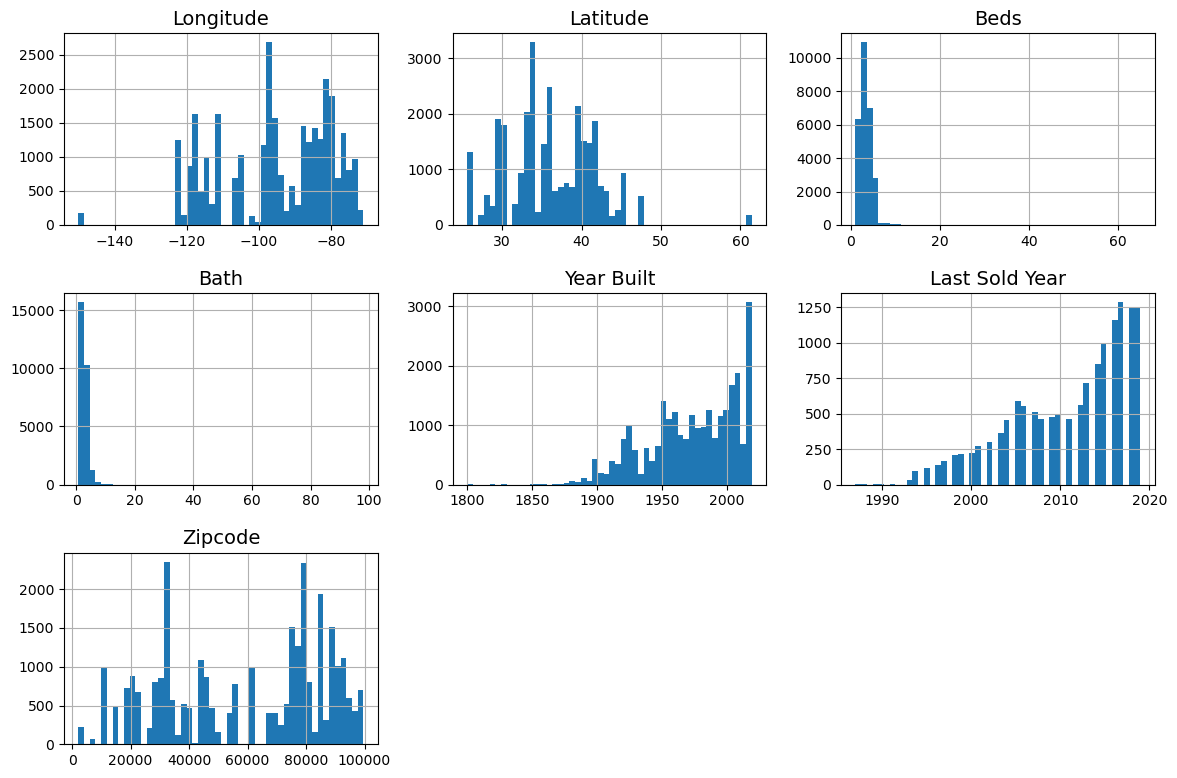

In [10]:
#code for the default font sizes
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

houseprice_raw.hist(bins=50, figsize=(12, 8))
save_fig("attribute_histogram_plots") #giving it a "fig_id = attribute_histogram_plots", and saving the figure in the images folder
plt.show()

I started by spending some time to explore and the date, and then visulaize it. These were the first steps I have done.

# Data Cleaning

In [11]:
import pandas as pd
from sklearn.impute import SimpleImputer

def clean_housing_data(houseprice_raw):
    #creating a copy to avoid changing the original raw data
    df_clean = houseprice_raw.copy()
    
    #dropping duplicates
    df_clean = df_clean.drop_duplicates()
    
    #dropping rows where Price is missing
    df_clean = df_clean.dropna(subset=['Price'])

    if 'Lot Size' in df_clean.columns:
        #detecting which rows contain acre
        is_acres = df_clean['Lot Size'].astype(str).str.contains('acre', case=False, na=False)
        
        #removing commas and extracting just the numbers/decimals
        df_clean['Lot Size'] = df_clean['Lot Size'].astype(str).str.replace(r'[a-zA-Z, ]', '', regex=True).str.strip()
        df_clean['Lot Size'] = pd.to_numeric(df_clean['Lot Size'], errors='coerce')
        
        #multiplying the rows with acres by 43,560 to convert acres to square feet
        df_clean.loc[is_acres, 'Lot Size'] *= 43560
    
    #cleaning columns by Removing $, commas, and text in the following columns: Price, Last Sold For, Sqr Ft, Lot Size
    cols_to_clean = ['Price', 'Last Sold For', 'Sqr Ft', 'Lot Size']
    for col in cols_to_clean:
        if col in df_clean.columns:
            # Removing letters, commas, and symbols
            df_clean[col] = df_clean[col].astype(str).str.replace(r'[a-zA-Z,$\+ ]', '', regex=True).str.strip()
            df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

    #filling missing Sqr Ft based on the median of the City
    if 'Sqr Ft' in df_clean.columns and 'City' in df_clean.columns:
        df_clean['Sqr Ft'] = df_clean.groupby('City')['Sqr Ft'].transform(
            lambda x: x.fillna(x.median())
        )
        #and if there are still rows that have a missing Sqr Ft(for example, a city had no Sqr Ft data at all), then we would fill the Sqr Ft of that city with a global median
        df_clean['Sqr Ft'] = df_clean['Sqr Ft'].fillna(df_clean['Sqr Ft'].median())
        
    #removing Outliers using the IQR Method for Price. startign first by calculating the upper and lower Quartiles
    Q1 = df_clean['Price'].quantile(0.25)
    Q3 = df_clean['Price'].quantile(0.75)
    #calucating the Interquartile range
    IQR = Q3 - Q1
    
    #defining the bounds according to the standard statistical threshold (1.5 * IQR is the standard statistical threshold)
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    #keeping only the rows that are within the bounds
    df_clean = df_clean[(df_clean['Price'] >= lower_bound) & (df_clean['Price'] <= upper_bound)]
    
    #grouping the columns that has continuous numerical data together because it makes sense to get their average for example size, and for example number of rooms)
    numeric_columns = ["Sqr Ft", "Lot Size", "Beds", "Bath", "Year Built"]

    #gruping the columns that are Categorical and has discrete data together, because I do not need to get the average of a zipcode, because it wouldn't make sense
    categorical_columns = ["Last Sold Year", "Zipcode", "Last Sold For"]

    #filling missing values using SimpleImputer, and using 'mean' for continuous numbers and 'most_frequent' for categorical/discrete data, so separating the columns into two lists based on their data type and how to handle them
    #so for numerical columns, filling missing values (NaNs) with the mathematical average (mean) of that column
    numeric_imputer = SimpleImputer(strategy="mean")
    #and for categorical columns, filling missing values with the most common value (mode) found in that column
    categorical_imputer = SimpleImputer(strategy="most_frequent")

    #calculating the mean for each numerical column and instantly replacing the missing values in the dataframe
    df_clean[numeric_columns] = numeric_imputer.fit_transform(df_clean[numeric_columns])

    #calculating the most frequent value for each categorical column and instantly replacing the missing values
    df_clean[categorical_columns] = categorical_imputer.fit_transform(df_clean[categorical_columns])
    
    return df_clean

In [12]:
#running the houseprice dataset cleaning function, and storing the cleaned data in the variable cleaned_houseprice
cleaned_houseprice = clean_housing_data(houseprice_raw)

In [13]:
#exporting the cleaned data to a new CSV file without the index column
cleaned_houseprice.to_csv("my_cleaned_houseprice.csv", index=False)

print(f"Data cleaned successfully! Remaining rows: {len(cleaned_houseprice)}")

Data cleaned successfully! Remaining rows: 27136


In [14]:
#taking a look at the data to confirm that count for each row is 27136 (2.713600e+04 is equal to 27136 )
cleaned_houseprice.describe()

,Price,Sqr Ft,Longitude,Latitude,Lot Size,Beds,Bath,Year Built,Last Sold Year,Last Sold For,Zipcode
count,2.713600e+04,2.713600e+04,27136.000000,27136.000000,2.713600e+04,27136.000000,27136.000000,27136.000000,27136.000000,2.713600e+04,27136.000000
mean,3.356991e+05,3.932841e+03,-94.797724,36.178851,9.319972e+04,3.188282,2.402090,1973.454961,2015.302513,1.823437e+05,59123.504275
std,2.211778e+05,2.192503e+05,15.031196,5.533689,4.742608e+06,1.181565,0.954944,31.674698,5.981218,7.440439e+05,26586.056509
min,1.000000e+00,1.000000e+00,-150.047160,25.550295,1.000000e+00,1.000000,0.750000,1800.000000,1989.000000,1.000000e+00,2110.000000
25%,1.750000e+05,1.289000e+03,-106.227594,32.714501,5.066000e+03,3.000000,2.000000,1954.000000,2014.000000,1.250000e+05,33143.000000
50%,2.850000e+05,1.761000e+03,-93.306225,36.030698,8.276000e+03,3.000000,2.000000,1973.454961,2019.000000,1.250000e+05,67216.500000
75%,4.499000e+05,2.348000e+03,-81.699280,40.010700,2.570040e+04,4.000000,3.000000,2001.000000,2019.000000,1.785000e+05,80904.000000
max,1.059000e+06,3.600380e+07,-70.997740,61.442024,5.502665e+08,64.000000,17.000000,2019.000000,2019.000000,1.200000e+08,99577.000000


After looking at the data again I found out that I need to add filters to the dataset becuase I noticed the maximum number of beds is 64, and it does not common to have a house that has 64 beds. Properties with 64 beds are not likely to be standard residential homes, and they could be hostels, hotels, or commercial estates. However, since in some rare cases some luxiourious residential homes can legally have this number of bedrooms. I have decided to stick to houses that have 15 or less bedrooms, as hostels can start with 16 or more bedrooms. Also, I noticed that I have a $1 house price, which is logically impossible. 

In [15]:
copy_cleaned = pd.read_csv('my_cleaned_houseprice.csv') #reading the cleaned dataset
houseprice_filtered = copy_cleaned.copy()

In [16]:
#creating a new, filtered dataframe by applying logical conditions
houseprice_filtered = copy_cleaned[
    #a house must have 15 or fewer beds and a price must be at least $10,000 
    (copy_cleaned['Beds'] <= 15) & (copy_cleaned['Price'] >= 10000)
]

#printting out how many rows we removed to clean up the data
rows_removed = len(copy_cleaned) - len(houseprice_filtered)
print(f"Removed {rows_removed} extreme outlier rows.")
print(f"Remaining clean data: {len(houseprice_filtered)} houses.")

#overwriting the cleaned dataframe with the dataframe thatt has beenn cleaned and has been filtered
housePrice_cleaned = houseprice_filtered.copy()

Removed 203 extreme outlier rows.
Remaining clean data: 26933 houses.


In [17]:
#taking a look at the data to confirm that count for each row is 26933 (2.693300e+04 is equal to 26933 )
housePrice_cleaned.describe()

,Price,Sqr Ft,Longitude,Latitude,Lot Size,Beds,Bath,Year Built,Last Sold Year,Last Sold For,Zipcode
count,2.693300e+04,2.693300e+04,26933.000000,26933.000000,2.693300e+04,26933.000000,26933.000000,26933.000000,26933.000000,2.693300e+04,26933.000000
mean,3.381989e+05,3.951417e+03,-94.859704,36.153204,9.377979e+04,3.184125,2.406740,1973.698750,2015.310437,1.830563e+05,59196.727658
std,2.201201e+05,2.200749e+05,15.052884,5.535346,4.760441e+06,1.061709,0.955314,31.584563,5.976815,7.467657e+05,26635.204959
min,1.000000e+04,1.000000e+00,-150.047160,25.550295,1.000000e+00,1.000000,0.750000,1800.000000,1989.000000,1.000000e+01,2110.000000
25%,1.790000e+05,1.292000e+03,-106.252110,32.707630,5.120000e+03,3.000000,2.000000,1955.000000,2014.000000,1.250000e+05,33141.000000
50%,2.890000e+05,1.764000e+03,-93.337780,36.022774,8.276000e+03,3.000000,2.000000,1973.454961,2019.000000,1.250000e+05,68022.000000
75%,4.499000e+05,2.353000e+03,-81.693680,39.989925,2.613600e+04,4.000000,3.000000,2001.000000,2019.000000,1.800000e+05,80906.000000
max,1.059000e+06,3.600380e+07,-70.997740,61.442024,5.502665e+08,15.000000,17.000000,2019.000000,2019.000000,1.200000e+08,99577.000000


In [18]:
#exporting the cleaned filtered data to a new CSV file without the index column
housePrice_cleaned.to_csv("my_cleaned_filtered_houseprice.csv", index=False)

After cleaning the houseprice dataset using a cleaning function and filtering to remove extreme outliers, I want to see the correlation between the columns of the dataset through a heatmap

# Data Exploration

## Correlation

In [19]:
#setting up a folder to save the images
IMAGES_PATH = Path() / "As1images" / "data_exploration" #appends images to the folder, and appends data_exploration as its subfolder
IMAGES_PATH.mkdir(parents=True, exist_ok=True) #creates the folder if it does not already exist

In [20]:
#function for saving figures to the As1images folder as high-res PNGs
def save_fig(figName, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{figName}.{fig_extension}"
    
    if tight_layout:
        #using tight_layout to automatically adjust the padding so axis labels don't get cut off.
        plt.tight_layout()
        
    #saving the image
    plt.savefig(path, format=fig_extension, dpi=resolution)

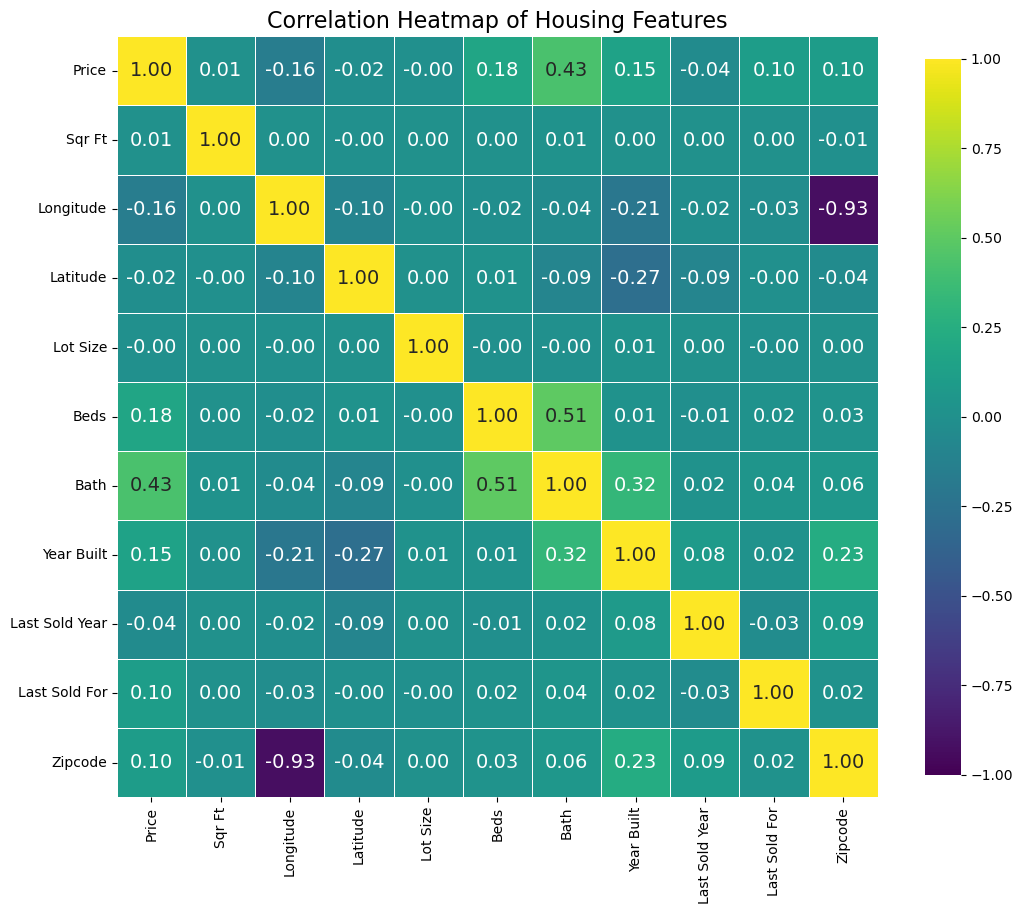

In [21]:
numerical_cols = cleaned_houseprice.select_dtypes(include=[np.number]).columns

#calculating the correlation matrix
corr_matrix = cleaned_houseprice[numerical_cols].corr()

#creating a geometric mask to hide the top right triangle, and that's to remove duplicate data

#setting up the figure size
plt.figure(figsize=(11, 10))

#drawing the heatmap
sns.heatmap(corr_matrix, cmap='viridis', vmax=1.0, vmin=-1.0, center=0, square=True, linewidths=.5, annot=True, fmt='.2f', cbar_kws={"shrink": .8})

plt.title('Correlation Heatmap of Housing Features', fontsize=16)
#saving the figure using the save_fig function
save_fig("correlation_heatmap")
#displaying the plot
plt.show()

### Looking at the price column on heatmap, I can see that:
#### bath and price have a positive relationship +0.43, 
#### and price and beds have a positive relationship of +0.18, 
#### and price and year built have a positive relationship of +0.15, 
#### and price and longitude have a negative relationship of -0.16, 
#### and price and last year sold have a negative relationship of -0.04.

Based on the correlation heatmap, I can understand that as the number of bathrooms goes up, the price is likely to go up. I can also see two other positive relationships and one negative that are not as strong as the number of bathrooms, but still can help predict the house price, and those three predictors are the Longitude, numbers of beds, and the the year built of the house. so while the number of bathrooms is a solid indicator of a property's value, features like the Longitude, the year it was built, or the number of bedrooms are too inconsistent to predict price reliably on their own

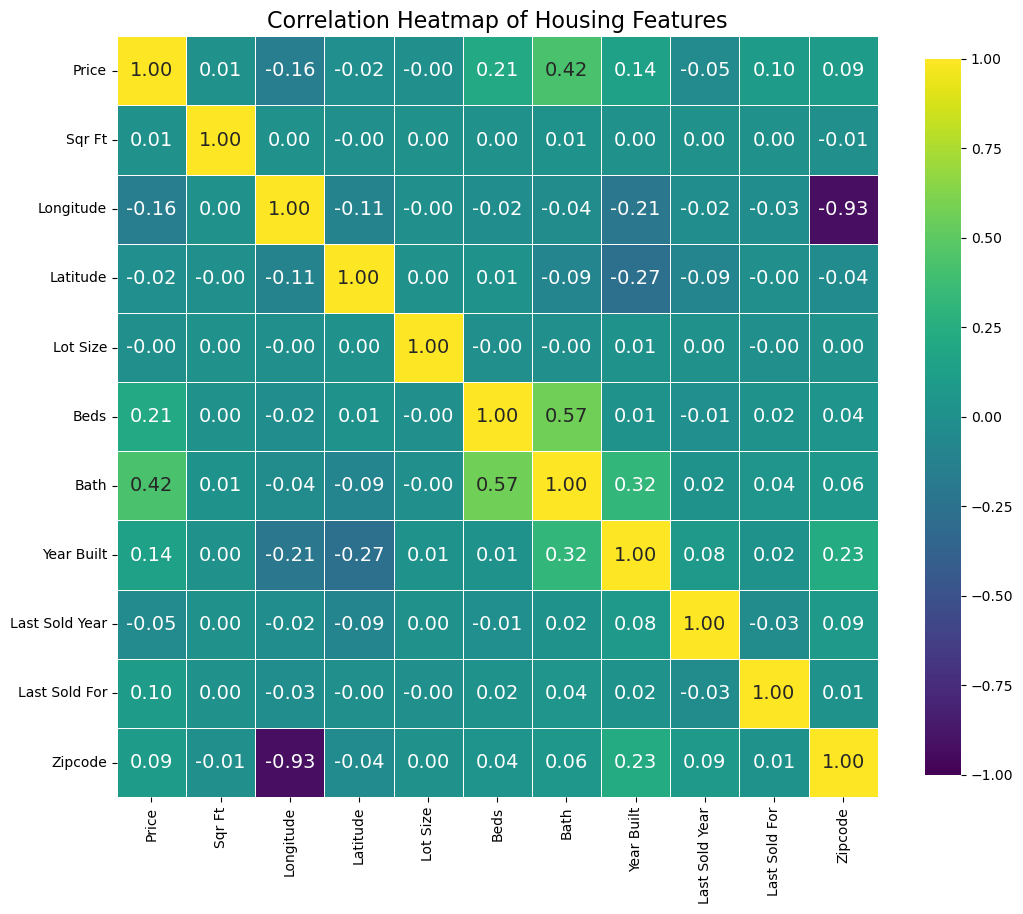

In [22]:
#selecting the numerical columns
numerical_cols = housePrice_cleaned.select_dtypes(include=[np.number]).columns

#calculating the correlation matrix
corr_matrix = housePrice_cleaned[numerical_cols].corr()

#creating a geometric mask to hide the top right triangle, and that's to remove duplicate data

#setting up the figure size
plt.figure(figsize=(11, 10))

#drawing the heatmap
sns.heatmap(corr_matrix, cmap='viridis', vmax=1.0, vmin=-1.0, center=0, square=True, linewidths=.5, annot=True, fmt='.2f', cbar_kws={"shrink": .8})

plt.title('Correlation Heatmap of Housing Features', fontsize=16)
#saving the figure using the save_fig function
save_fig("correlation_heatmap_filteredData")
#displaying the plot
plt.show()

### Looking at the price column on heatmap, I can see that:
#### bath and price have a positive relationship +0.42, 
#### and price and beds have a positive relationship of +0.21, 
#### and price and year built have a positive relationship of +0.14, 
#### and price and longitude have a negative relationship of -0.16, 
#### and price and last year sold have a negative relationship of -0.04.

Based on the correlation heatmap on the filtered data, where data have been cleaned of extreme outliners in the beds column. I can confirm that as the number of bathrooms goes up, the price to go up. The correlation matrix confirms that the number of bathrooms (0.42) and bedrooms (0.21) are the most reliable indicators of property value, indicating that room count is a critical selling point in this specific market

In [23]:
#calculating the correlation matrix for numeric columns
correlation_matrix = housePrice_cleaned.corr(numeric_only=True)
#printing how strongly each feature correlates with the Price column
print(correlation_matrix['Price'].sort_values(ascending=False))

Price             1.000000
Bath              0.423988
Beds              0.206163
Year Built        0.141493
Last Sold For     0.101091
Zipcode           0.094708
Sqr Ft            0.005138
Lot Size         -0.004169
Latitude         -0.015047
Last Sold Year   -0.047586
Longitude        -0.159253
Name: Price, dtype: float64


## Scatter Plots

### Price and Number of bathrooms

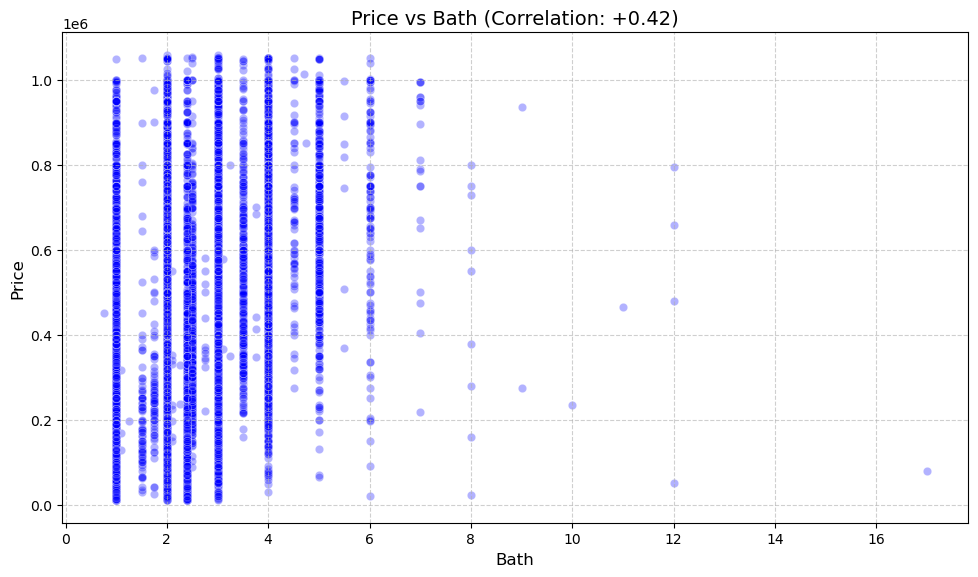

In [24]:
#plotting the relationship between price and number of bathrroms
plt.figure(figsize=(10, 6))
#using alpha=0.3 to make the overlappin points darker, and that's to show density
sns.scatterplot(data=housePrice_cleaned, x='Bath', y='Price', alpha=0.3, color='blue')

plt.title('Price vs Bath (Correlation: +0.42)', fontsize=14)
plt.xlabel('Bath', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

#saving the figure using the save_fig function
save_fig("price_vs_bath_scatter")
#displaying the plot
plt.show()

from the scatter plot between price and the number of bathrooms, I can see that the majority of houses consists of standard homes with 1 to 6 bathrooms. Homes with 7 or more bathrooms are rare and represent a separate, luxury tier of the market.

from the scatter plot between price and the number of bathrooms, There is also a visible trend showing that as the number of bathrooms increases, the baseline price of the home increases as well. This visually confirms the heatmap findings, proving to the business that the number of bathrooms is a highly reliable feature for predicting a property's value.

### Price and Number of bedrooms

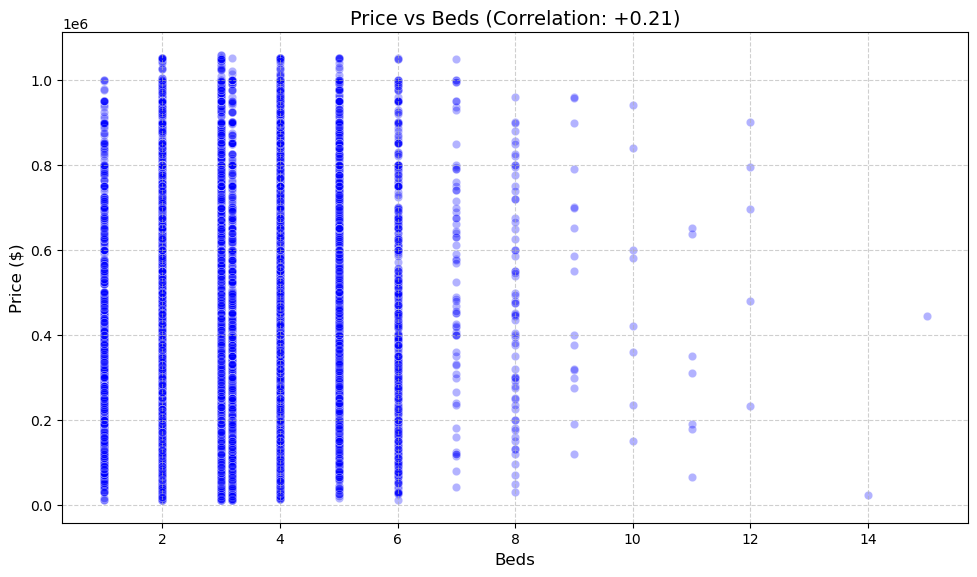

In [25]:
#plotting the relationship between price and number of bedrooms
plt.figure(figsize=(10, 6))
sns.scatterplot(data=housePrice_cleaned, x='Beds', y='Price', alpha=0.3, color='blue')

plt.title('Price vs Beds (Correlation: +0.21)', fontsize=14)
plt.xlabel('Beds', fontsize=12)
plt.ylabel('Price ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

#saving the figure using the save_fig function
save_fig("price_vs_bath_scatter")
#displaying the plot
plt.show()

from visualizing the scatter plot between price and the number of bedrooms, I can conclude the relationship between Price and Bedrooms (+0.21) reveals a wide highly dispersed vertical spread. For instance, homes with 3 bedrooms span almost the entire price spectrum, visually confirming that bedroom count alone is too weak of a predictor to accurately price a home.

# More Data Cleaning

In [26]:
housePrice_More_cleaned = houseprice_filtered.copy()

In [27]:
#selectign a string and assigning it to the variable Sqr_Ft
Sqr_Ft = ['Sqr Ft']

#creating a function for applying IQR method to Sqr Ft
def apply_iqr_filter(housePrice_More_cleaned, Sqr_Ft):
    #removing Outliers using the IQR Method for Price. startign first by calculating the upper and lower Quartiles
    Q1 = housePrice_More_cleaned[Sqr_Ft].quantile(0.25)
    Q3 = housePrice_More_cleaned[Sqr_Ft].quantile(0.75)
    #calucating the Interquartile range
    IQR = Q3 - Q1
    
    #defining the bounds according to the standard statistical threshold (1.5 * IQR is the standard statistical threshold)
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    #returning a filtered data keeping only the rows within the bounds
    return housePrice_More_cleaned[(housePrice_More_cleaned[Sqr_Ft] >= lower_bound) & (housePrice_More_cleaned[Sqr_Ft] <= upper_bound)]

housePrice_More_cleaned = apply_iqr_filter(housePrice_More_cleaned, 'Sqr Ft')

#checing how many extreme outliers were removed
print(f"Original dataset rows: {len(houseprice_filtered)}")
print(f"Cleaned alternative dataset rows: {len(housePrice_More_cleaned)}")

Original dataset rows: 26933
Cleaned alternative dataset rows: 25932


I can see that after I have removed the outliners in the Sqr Ft column, now I can see that I have removed just over 1000 rows of outlines

In [28]:
#exporting the more cleaned filtered data to a new CSV file without the index column
housePrice_More_cleaned.to_csv("more_cleaned_filtered_houseprice.csv", index=False)

# Exploring the more cleaned data

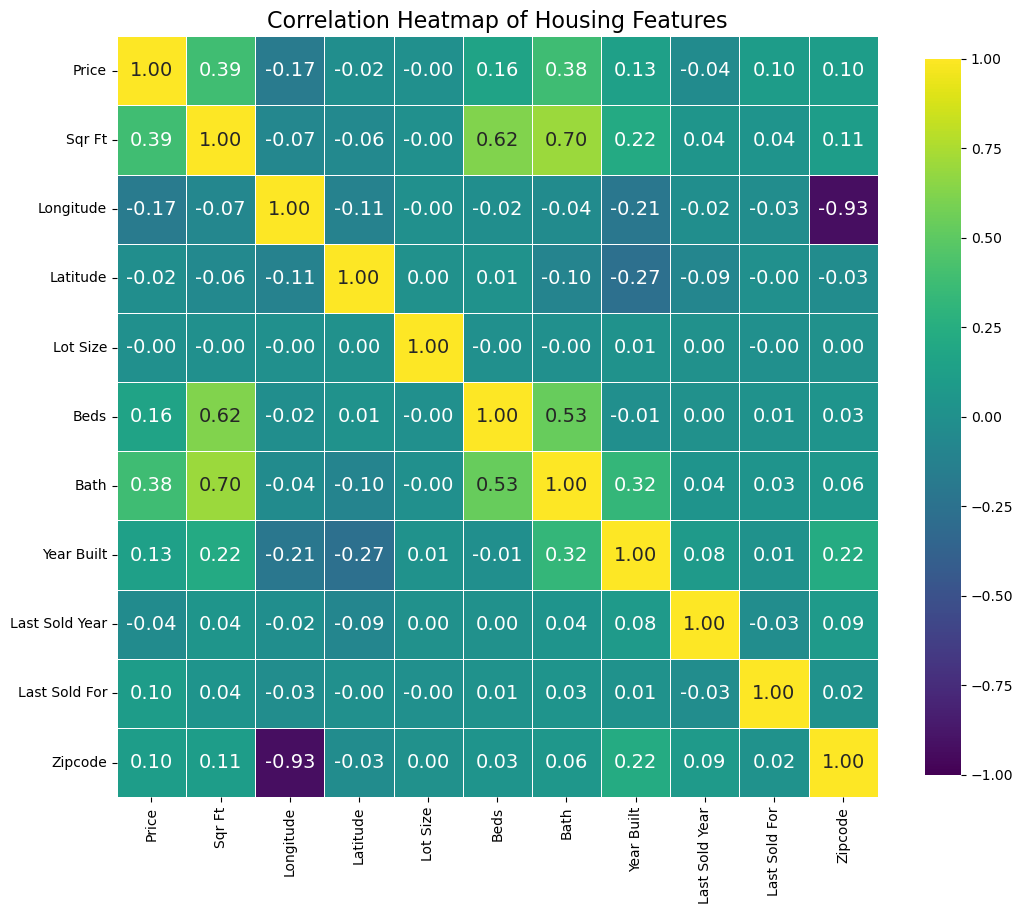

In [29]:
#selecting the numerical columns
numerical_cols = housePrice_More_cleaned.select_dtypes(include=[np.number]).columns

#calculating the correlation matrix
corr_matrix = housePrice_More_cleaned[numerical_cols].corr()

#creating a geometric mask to hide the top right triangle, and that's to remove duplicate data

#setting up the figure size
plt.figure(figsize=(11, 10))

#drawing the heatmap
sns.heatmap(corr_matrix, cmap='viridis', vmax=1.0, vmin=-1.0, center=0, square=True, linewidths=.5, annot=True, fmt='.2f', cbar_kws={"shrink": .8})

plt.title('Correlation Heatmap of Housing Features', fontsize=16)
#saving the figure using the save_fig function
save_fig("correlation_heatmap_filteredData")
#displaying the plot
plt.show()

### Looking at the price column on heatmap, I can see that:
#### Sqr Ft and price have a positive relationship +0.39, 
#### bath and price have a positive relationship +0.38, 
#### and price and beds have a positive relationship of +0.16, 
#### and price and year built have a positive relationship of +0.13, 
#### and price and longitude have a negative relationship of -0.17

Based on the correlation heatmap, I can understand that as the number of Sqr Ft goes up, the price is likely to go up. Also as the number of bathrooms goes up, the price is likely to go up. I can also see two other positive relationships and one negative that are not as strong as the house Sqr Ft and number of bathrooms, but still can help predict the house price, and those three predictors are the Longitude, numbers of beds, and the the year built of the house. so while the house Sqr Ft and the number of bathrooms is a solid indicator of a property's value, features like the Longitude, the year it was built, or the number of bedrooms are too inconsistent to predict price reliably on their own

## Scatter Plots

### Price and Sqr Ft

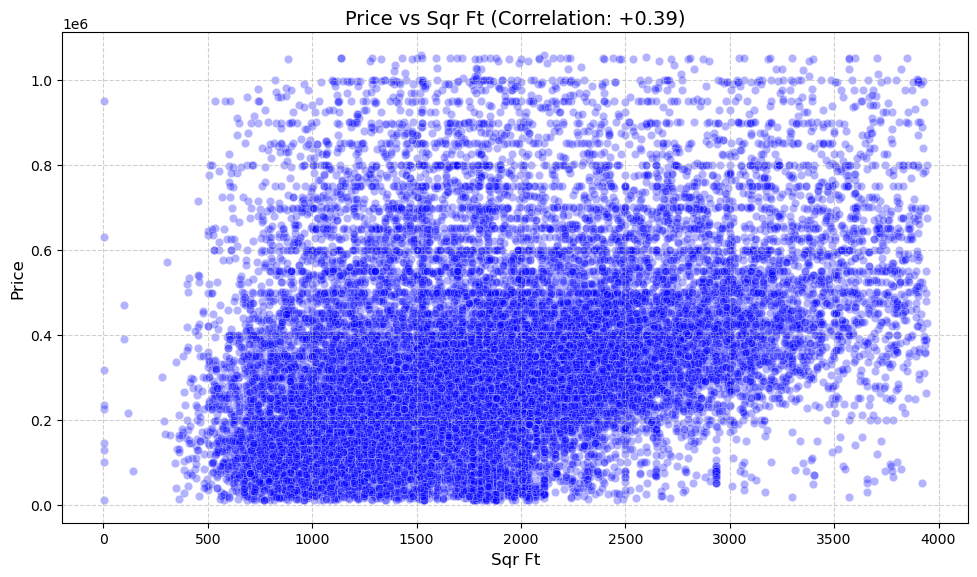

In [30]:
#plotting the relationship between price and square feet of the house
plt.figure(figsize=(10, 6))
#using alpha=0.3 to make the overlappin points darker, and that's to show density
sns.scatterplot(data=housePrice_More_cleaned, x='Sqr Ft', y='Price', alpha=0.3, color='blue')

plt.title('Price vs Sqr Ft (Correlation: +0.39)', fontsize=14)
plt.xlabel('Sqr Ft', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

#saving the figure using the save_fig function
save_fig("price_vs_Sqr Ft_scatter")
#displaying the plot
plt.show()

### Price and Number of bathrooms

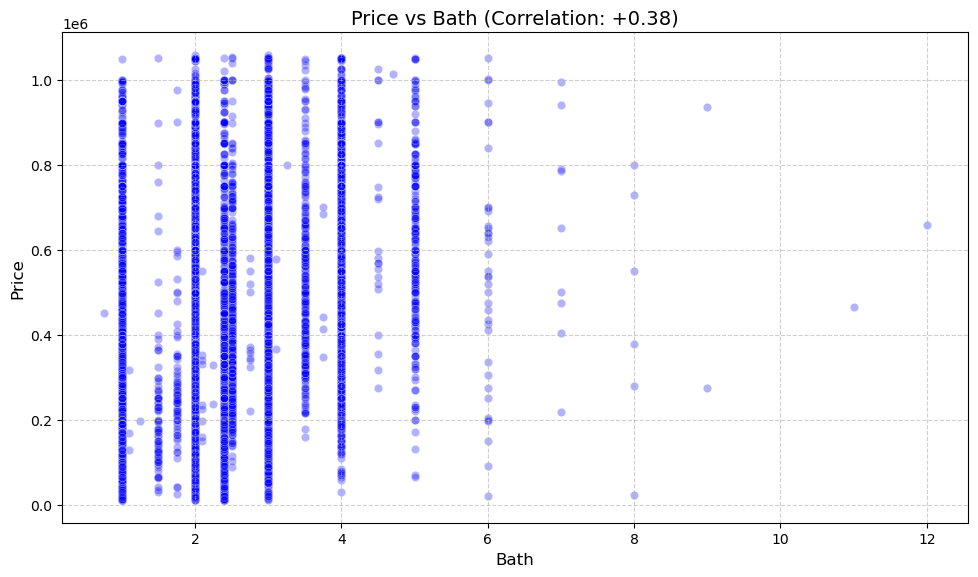

In [31]:
#plotting the relationship between price and number of bathrroms
plt.figure(figsize=(10, 6))
#using alpha=0.3 to make the overlappin points darker, and that's to show density
sns.scatterplot(data=housePrice_More_cleaned, x='Bath', y='Price', alpha=0.3, color='blue')

plt.title('Price vs Bath (Correlation: +0.38)', fontsize=14)
plt.xlabel('Bath', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

#saving the figure using the save_fig function
save_fig("price_vs_bath_scatter")
#displaying the plot
plt.show()